# EDA (memoria)

### **Business understanding**


Trabajando para un estudio de videojuegos, parece que no acertamos del todo en el marco de lanzamiento y que clase de juego es el que a la gente le interesa.

---


### **Hipótesis.**


Lamentablemente, a fecha de hoy, decir que *"Vamos a lanzar un juego del genero "DEPORTES"*, no nos convierte en el lapiz mas afilado del estuche, por lo que nuestra hipotesis es que, si lanzamos un juego de genero **"Shooter"** en el mes de **Septiembre-Octubre**, tendremos un exito asegurado.

---

### **Requerimiento de los datos**


Los datos que necesitamos son:
- Fecha de lanzamiento
- Genero
- Unidades vendidas

---
### **Obtención de los datos**


Para obtener los datos, me he informado sobre como acceder a la api de Steam, pero parece ser que son bastante restrictivos en este aspecto, por hacer incluso 5 peticiones unicamente te pueden bloquear.

Por lo que, he optado por buscar los datos en Kaggle, y he encontrado un dataset que contiene todos los juegos de Steam, y se actualiza diariamente, por lo que me es muy util.

https://www.kaggle.com/datasets/hubertsidorowicz/steam-games-dataset-daily-updates/data

---

### **Codigo**

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import sys
import pyarrow
import json
import ast

sys.path.insert(0, "../utils/")
import utils
import importlib
importlib.reload(utils)

<module 'utils' from '/Users/amber/LocalDrive/Bootcamp Data Science/DS-EDA/src/notebooks/../utils/utils.py'>

In [2]:
## Creamos el data_set con los datos del csv
df = pd.read_csv("../data/archive/steam_games.csv", low_memory=False)

In [3]:
df

,app_id,name,release_date,price,price_status,estimated_owners,developers,publishers,genres,categories,...,linux,header_image,screenshots,movies,website,support_url,support_email,metacritic_url,steam_store_available,steam_spy_available
0,2516390,SpaceBase Power-天基火力,2024-06-06,4.99,paid,0 - 20000,"[""domiiyo""]","[""domiiyo""]","[""Casual"", ""Indie"", ""Racing""]","[""Single-player"", ""Family Sharing""]",...,False,https://shared.akamai.steamstatic.com/store_it...,"[""https://shared.akamai.steamstatic.com/store_...",[],https://space.bilibili.com/361097030/video,NaN,48182207@qq.com,NaN,True,True
1,2516430,Cyborg3003,2024-08-15,16.99,paid,20000 - 50000,"[""Rodrigo Banzato""]","[""Rodrigo Banzato""]","[""Action"", ""Adventure"", ""Indie""]","[""Single-player"", ""Multi-player"", ""Co-op"", ""On...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[""https://shared.akamai.steamstatic.com/store_...",[],https://www.rodrigobanzato.com,https://www.cyborg3003.com,gamecyborg3003@gmail.com,NaN,True,True
2,2516470,Weird RPG 2,2026-01-22,9.99,paid,"0 .. 20,000","[""yuzhen""]","[""yuzhen""]","[""Action"", ""Adventure"", ""RPG""]","[""Single-player"", ""Steam Achievements"", ""Full ...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257270133, ""name"": ""gameTrailer"", ""thu...",NaN,NaN,13000590@qq.com,NaN,True,True
3,2516530,Galvanic Bride,2023-10-20,10.99,paid,0 - 20000,"[""IA GAMES""]","[""IA GAMES""]","[""Action"", ""Adventure"", ""Indie""]","[""Single-player"", ""Family Sharing""]",...,False,https://shared.akamai.steamstatic.com/store_it...,"[""https://shared.akamai.steamstatic.com/store_...",[],https://link.tumblbug.com/zEiffqcuoBb,NaN,itisalivegames@gmail.com,NaN,True,True
4,2516540,HeroTower,2023-08-08,0.99,paid,0 - 20000,"[""CZ Game""]","[""CZ Game""]","[""Action"", ""Casual"", ""Indie"", ""RPG"", ""Early Ac...","[""Single-player"", ""Family Sharing""]",...,False,https://shared.akamai.steamstatic.com/store_it...,"[""https://shared.akamai.steamstatic.com/store_...",[],NaN,NaN,329817174@qq.com,NaN,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144345,1081140,Zombies war,2019-05-21,1.99,paid,"0 .. 20,000","[""JY""]","[""JY""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 256749801, ""name"": ""01"", ""thumbnail"": ...",NaN,NaN,455897238@qq.com,NaN,True,True
144346,1081260,Crisis of the Middle Ages,2019-05-29,0.99,paid,"0 .. 20,000","[""OrgAction LLC""]","[""OrgAction LLC""]","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 256751936, ""name"": ""Crisis of the Midd...",https://orgaction.itch.io/crisis-of-the-middle...,NaN,jam@orgaction.com,NaN,True,True
144347,1081410,GourMelee,2019-06-06,7.99,paid,"0 .. 20,000","[""Anthony Tesija""]","[""ATesh Games""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 1, ""description"": ""Multi-player""}, {""i...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 256750554, ""name"": ""GourMelee Trailer""...",http://gourmelee.com,NaN,ateshgames@gmail.com,NaN,True,True
144348,1081430,Tale Of Starship,2019-11-15,2.99,paid,"0 .. 20,000","[""Mathieu GUERARD""]","[""Mathieu GUERARD""]","[{""id"": ""23"", ""description"": ""Indie""}]","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 256765266, ""name"": ""Trailer Tale Of St...",NaN,N

In [4]:
df.dtypes

app_id                        int64
name                            str
release_date                    str
price                       float64
price_status                    str
estimated_owners                str
developers                      str
publishers                      str
genres                          str
categories                      str
tags                            str
positive                      int64
negative                      int64
recommendations             float64
peak_ccu                      int64
metacritic_score            float64
user_score                    int64
average_playtime_forever      int64
median_playtime_forever       int64
average_playtime_2weeks       int64
median_playtime_2weeks        int64
short_description               str
about_the_game                  str
detailed_description            str
notes                           str
achievements                float64
dlc_count                     int64
packages                    

Tremenda cantidad de datos que hay, vamos a limpiarlo un poquito, ya que asi no no se puede subir al git. (Y que no me son necesarios todos)

In [5]:
df_acotada = df[["release_date","estimated_owners","genres"]]

df_acotada

,release_date,estimated_owners,genres
0,2024-06-06,0 - 20000,"[""Casual"", ""Indie"", ""Racing""]"
1,2024-08-15,20000 - 50000,"[""Action"", ""Adventure"", ""Indie""]"
2,2026-01-22,"0 .. 20,000","[""Action"", ""Adventure"", ""RPG""]"
3,2023-10-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie""]"
4,2023-08-08,0 - 20000,"[""Action"", ""Casual"", ""Indie"", ""RPG"", ""Early Ac..."
...,...,...,...
144345,2019-05-21,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ..."
144346,2019-05-29,"0 .. 20,000","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ..."
144347,2019-06-06,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ..."
144348,2019-11-15,"0 .. 20,000","[{""id"": ""23"", ""description"": ""Indie""}]"


Creo que con acotar los datos y quedarnos con solamente con los juegos lanzados de 2023 a 2025, podemos sacar la conclusion de mejor forma.

In [6]:
df_acotada["release_date"] = pd.to_datetime(df_acotada["release_date"],format='%Y-%m-%d')

df_acotada

,release_date,estimated_owners,genres
0,2024-06-06,0 - 20000,"[""Casual"", ""Indie"", ""Racing""]"
1,2024-08-15,20000 - 50000,"[""Action"", ""Adventure"", ""Indie""]"
2,2026-01-22,"0 .. 20,000","[""Action"", ""Adventure"", ""RPG""]"
3,2023-10-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie""]"
4,2023-08-08,0 - 20000,"[""Action"", ""Casual"", ""Indie"", ""RPG"", ""Early Ac..."
...,...,...,...
144345,2019-05-21,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ..."
144346,2019-05-29,"0 .. 20,000","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ..."
144347,2019-06-06,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ..."
144348,2019-11-15,"0 .. 20,000","[{""id"": ""23"", ""description"": ""Indie""}]"


In [7]:
condicion = df_acotada["release_date"].dt.year >= 2023
condicion2 = df_acotada["release_date"].dt.year <= 2025

df_acotada = df_acotada.loc[condicion & condicion2, :]
df_acotada

,release_date,estimated_owners,genres
0,2024-06-06,0 - 20000,"[""Casual"", ""Indie"", ""Racing""]"
1,2024-08-15,20000 - 50000,"[""Action"", ""Adventure"", ""Indie""]"
3,2023-10-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie""]"
4,2023-08-08,0 - 20000,"[""Action"", ""Casual"", ""Indie"", ""RPG"", ""Early Ac..."
5,2024-05-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie"", ""RPG""]"
...,...,...,...
144258,2023-10-17,"20,000 .. 50,000","[{""id"": ""28"", ""description"": ""Simulation""}, {""..."
144264,2023-12-13,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ..."
144309,2023-02-27,"0 .. 20,000","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ..."
144324,2023-02-28,"20,000 .. 50,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ..."


In [8]:
# Convertimos los generos a string
df_acotada = df_acotada
df_acotada["genres"] = df_acotada["genres"].astype("string")

df_acotada

,release_date,estimated_owners,genres
0,2024-06-06,0 - 20000,"[""Casual"", ""Indie"", ""Racing""]"
1,2024-08-15,20000 - 50000,"[""Action"", ""Adventure"", ""Indie""]"
3,2023-10-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie""]"
4,2023-08-08,0 - 20000,"[""Action"", ""Casual"", ""Indie"", ""RPG"", ""Early Ac..."
5,2024-05-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie"", ""RPG""]"
...,...,...,...
144258,2023-10-17,"20,000 .. 50,000","[{""id"": ""28"", ""description"": ""Simulation""}, {""..."
144264,2023-12-13,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ..."
144309,2023-02-27,"0 .. 20,000","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ..."
144324,2023-02-28,"20,000 .. 50,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ..."


In [9]:
# Vamos a separar "estimated_owners", ya que es un rango y no podemos usarlo correctamente.
df_acotada[["estimated_owners_min", "estimated_owners_max"]] = (
    df_acotada["estimated_owners"].str.split(r" - | \.\. ", expand=True)
)

df_acotada

,release_date,estimated_owners,genres,estimated_owners_min,estimated_owners_max
0,2024-06-06,0 - 20000,"[""Casual"", ""Indie"", ""Racing""]",0,20000
1,2024-08-15,20000 - 50000,"[""Action"", ""Adventure"", ""Indie""]",20000,50000
3,2023-10-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie""]",0,20000
4,2023-08-08,0 - 20000,"[""Action"", ""Casual"", ""Indie"", ""RPG"", ""Early Ac...",0,20000
5,2024-05-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie"", ""RPG""]",0,20000
...,...,...,...,...,...
144258,2023-10-17,"20,000 .. 50,000","[{""id"": ""28"", ""description"": ""Simulation""}, {""...","20,000","50,000"
144264,2023-12-13,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...",0,"20,000"
144309,2023-02-27,"0 .. 20,000","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ...",0,"20,000"
144324,2023-02-28,"20,000 .. 50,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","20,000","50,000"


In [10]:
# Algunos owners estan mal (ejemplo "20,000"), por lo que no puedo cambiar a numerico
min_arreglados = df_acotada["estimated_owners_min"].apply(utils.arreglar_owners)
df_acotada["estimated_owners_min"] = min_arreglados

max_arreglados = df_acotada["estimated_owners_max"].apply(utils.arreglar_owners)
df_acotada["estimated_owners_max"] = max_arreglados

In [11]:
# Los paso a numericos

df_acotada["estimated_owners_min"] = pd.to_numeric(df_acotada["estimated_owners_min"])
df_acotada["estimated_owners_max"] = pd.to_numeric(df_acotada["estimated_owners_max"])

In [12]:
# Vamos a comprobar duplicados

df_acotada.duplicated().sum()

np.int64(16389)

In [13]:
# Vamos a cambiar los generos vacios por "Desconocido"
# Pero primero df_acotada a df, para agilizar

df = df_acotada

In [14]:
# Algunos datos estan en formato JSON por alguna razón, vamos a sacarlos
lista_generos = df['genres'].astype(str).apply(lambda x: json.loads(x) if x.startswith('[') else [])

# Vamos a extraer el genero, respetando los vacios
nombres_generos = lista_generos.apply(lambda x: [utils.extraer_valor(item) for item in x] if isinstance(x, list) else [])

# Expandir en múltiples columnas y limpiar nulos
gnr_extraidos = nombres_generos.apply(pd.Series).fillna('Desconocido').astype(str)

# Generamos columnas segun cantidad max y unirlas al DataFrame original
gnr_extraidos.columns = [f'genre_{i}' for i in range(gnr_extraidos.shape[1])]
df = pd.concat([df, gnr_extraidos], axis=1)

In [15]:
# Y tambien vamos a crear una columna "mes" para comparar
df["month"] = df["release_date"].dt.month

df

,release_date,estimated_owners,genres,estimated_owners_min,estimated_owners_max,genre_0,genre_1,genre_2,genre_3,genre_4,genre_5,genre_6,genre_7,genre_8,genre_9,genre_10,month
0,2024-06-06,0 - 20000,"[""Casual"", ""Indie"", ""Racing""]",0,20000,Casual,Indie,Racing,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,6
1,2024-08-15,20000 - 50000,"[""Action"", ""Adventure"", ""Indie""]",20000,50000,Action,Adventure,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,8
3,2023-10-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie""]",0,20000,Action,Adventure,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,10
4,2023-08-08,0 - 20000,"[""Action"", ""Casual"", ""Indie"", ""RPG"", ""Early Ac...",0,20000,Action,Casual,Indie,RPG,Early Access,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,8
5,2024-05-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie"", ""RPG""]",0,20000,Action,Adventure,Indie,RPG,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144258,2023-10-17,"20,000 .. 50,000","[{""id"": ""28"", ""description"": ""Simulation""}, {""...",20000,50000,Simulation,Strategy,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,10
144264,2023-12-13,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...",0,20000,Action,Adventure,Casual,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,12
144309,2023-02-27,"0 .. 20,000","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ...",0,20000,Casual,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,2
144324,2023-02-28,"20,000 .. 50,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...",20000,50000,Action,Indie,RPG,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,2


In [16]:
# Hay valores de "estimated_owners_max" que tienen 0
# Estos no nos sirven

df_limpia = df[df["estimated_owners_max"] <= 0]
df_limpia

,release_date,estimated_owners,genres,estimated_owners_min,estimated_owners_max,genre_0,genre_1,genre_2,genre_3,genre_4,genre_5,genre_6,genre_7,genre_8,genre_9,genre_10,month
10,2023-09-07,0 - 0,"[""Casual""]",0,0,Casual,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,9
15,2025-02-07,0 - 0,"[""Casual"", ""Indie"", ""Simulation"", ""Free To Play""]",0,0,Casual,Indie,Simulation,Free To Play,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,2
16,2025-02-28,0 - 0,"[""Casual"", ""Indie"", ""Simulation"", ""Free To Play""]",0,0,Casual,Indie,Simulation,Free To Play,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,2
31,2023-08-01,0 - 0,"[""Action"", ""Free To Play""]",0,0,Action,Free To Play,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,8
38,2024-01-08,0 - 0,"[""Adventure"", ""Indie"", ""RPG"", ""Strategy""]",0,0,Adventure,Indie,RPG,Strategy,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128179,2025-04-21,0 - 0,"[""Adventure"", ""Simulation""]",0,0,Adventure,Simulation,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,4
128180,2025-07-13,0 - 0,"[""Action"", ""Adventure"", ""Casual"", ""Indie""]",0,0,Action,Adventure,Casual,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,7
128181,2025-11-21,0 - 0,"[""Casual"", ""Free To Play""]",0,0,Casual,Free To Play,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,11
128183,2025-10-24,0 - 0,"[""Adventure"", ""Casual"", ""Indie"", ""RPG""]",0,0,Adventure,Casual,Indie,RPG,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,10


In [17]:
df = df.drop(df_limpia.index)
df

,release_date,estimated_owners,genres,estimated_owners_min,estimated_owners_max,genre_0,genre_1,genre_2,genre_3,genre_4,genre_5,genre_6,genre_7,genre_8,genre_9,genre_10,month
0,2024-06-06,0 - 20000,"[""Casual"", ""Indie"", ""Racing""]",0,20000,Casual,Indie,Racing,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,6
1,2024-08-15,20000 - 50000,"[""Action"", ""Adventure"", ""Indie""]",20000,50000,Action,Adventure,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,8
3,2023-10-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie""]",0,20000,Action,Adventure,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,10
4,2023-08-08,0 - 20000,"[""Action"", ""Casual"", ""Indie"", ""RPG"", ""Early Ac...",0,20000,Action,Casual,Indie,RPG,Early Access,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,8
5,2024-05-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie"", ""RPG""]",0,20000,Action,Adventure,Indie,RPG,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144258,2023-10-17,"20,000 .. 50,000","[{""id"": ""28"", ""description"": ""Simulation""}, {""...",20000,50000,Simulation,Strategy,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,10
144264,2023-12-13,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...",0,20000,Action,Adventure,Casual,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,12
144309,2023-02-27,"0 .. 20,000","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ...",0,20000,Casual,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,2
144324,2023-02-28,"20,000 .. 50,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...",20000,50000,Action,Indie,RPG,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,2


Limpieza completada!

### Empezamos con el Analisis Univariante.

In [18]:
# Vamos empezando a analizar su cardinalidad

df_cardinalidad = pd.DataFrame([df.nunique(), df.nunique()/len(df) * 100, df.dtypes]).T.rename(columns = {0: "Card",\
                                                                                                    1: "%_Card", 2: "Tipo"})
df_cardinalidad

,Card,%_Card,Tipo
release_date,1094,2.624949,datetime64[us]
estimated_owners,23,0.055186,str
genres,1613,3.87024,string
estimated_owners_min,12,0.028793,int64
estimated_owners_max,12,0.028793,int64
genre_0,23,0.055186,str
genre_1,23,0.055186,str
genre_2,22,0.052787,str
genre_3,21,0.050388,str
genre_4,20,0.047988,str


**En nuestro caso, en nuestro analisis, las columnas target son "generos", "estimated_owners_min", "estimated_owners_max" y "month"**

In [19]:
# Vamos a pasar a lista las variables categoricas

categoricas_generos = []

for i in range(11):
    categoricas_generos.append("genre_" + str(i))

In [20]:
# Frecuencias absolutas

for columna in categoricas_generos:
    print(df[columna].value_counts(), "\n")

genre_0
Action                   16435
Casual                    9212
Adventure                 9023
Indie                     4115
Simulation                 892
RPG                        767
Strategy                   579
Racing                     185
Utilities                   78
Animation & Modeling        73
Sports                      62
Free To Play                53
Design & Illustration       46
Desconocido                 42
Massively Multiplayer       38
Audio Production            23
Education                   18
Early Access                10
Video Production            10
Photo Editing                8
Game Development             4
Software Training            3
Accounting                   1
Name: count, dtype: int64 

genre_1
Indie                    13476
Adventure                 8069
Casual                    6981
Desconocido               6016
Simulation                2081
RPG                       1844
Strategy                  1477
Early Access              

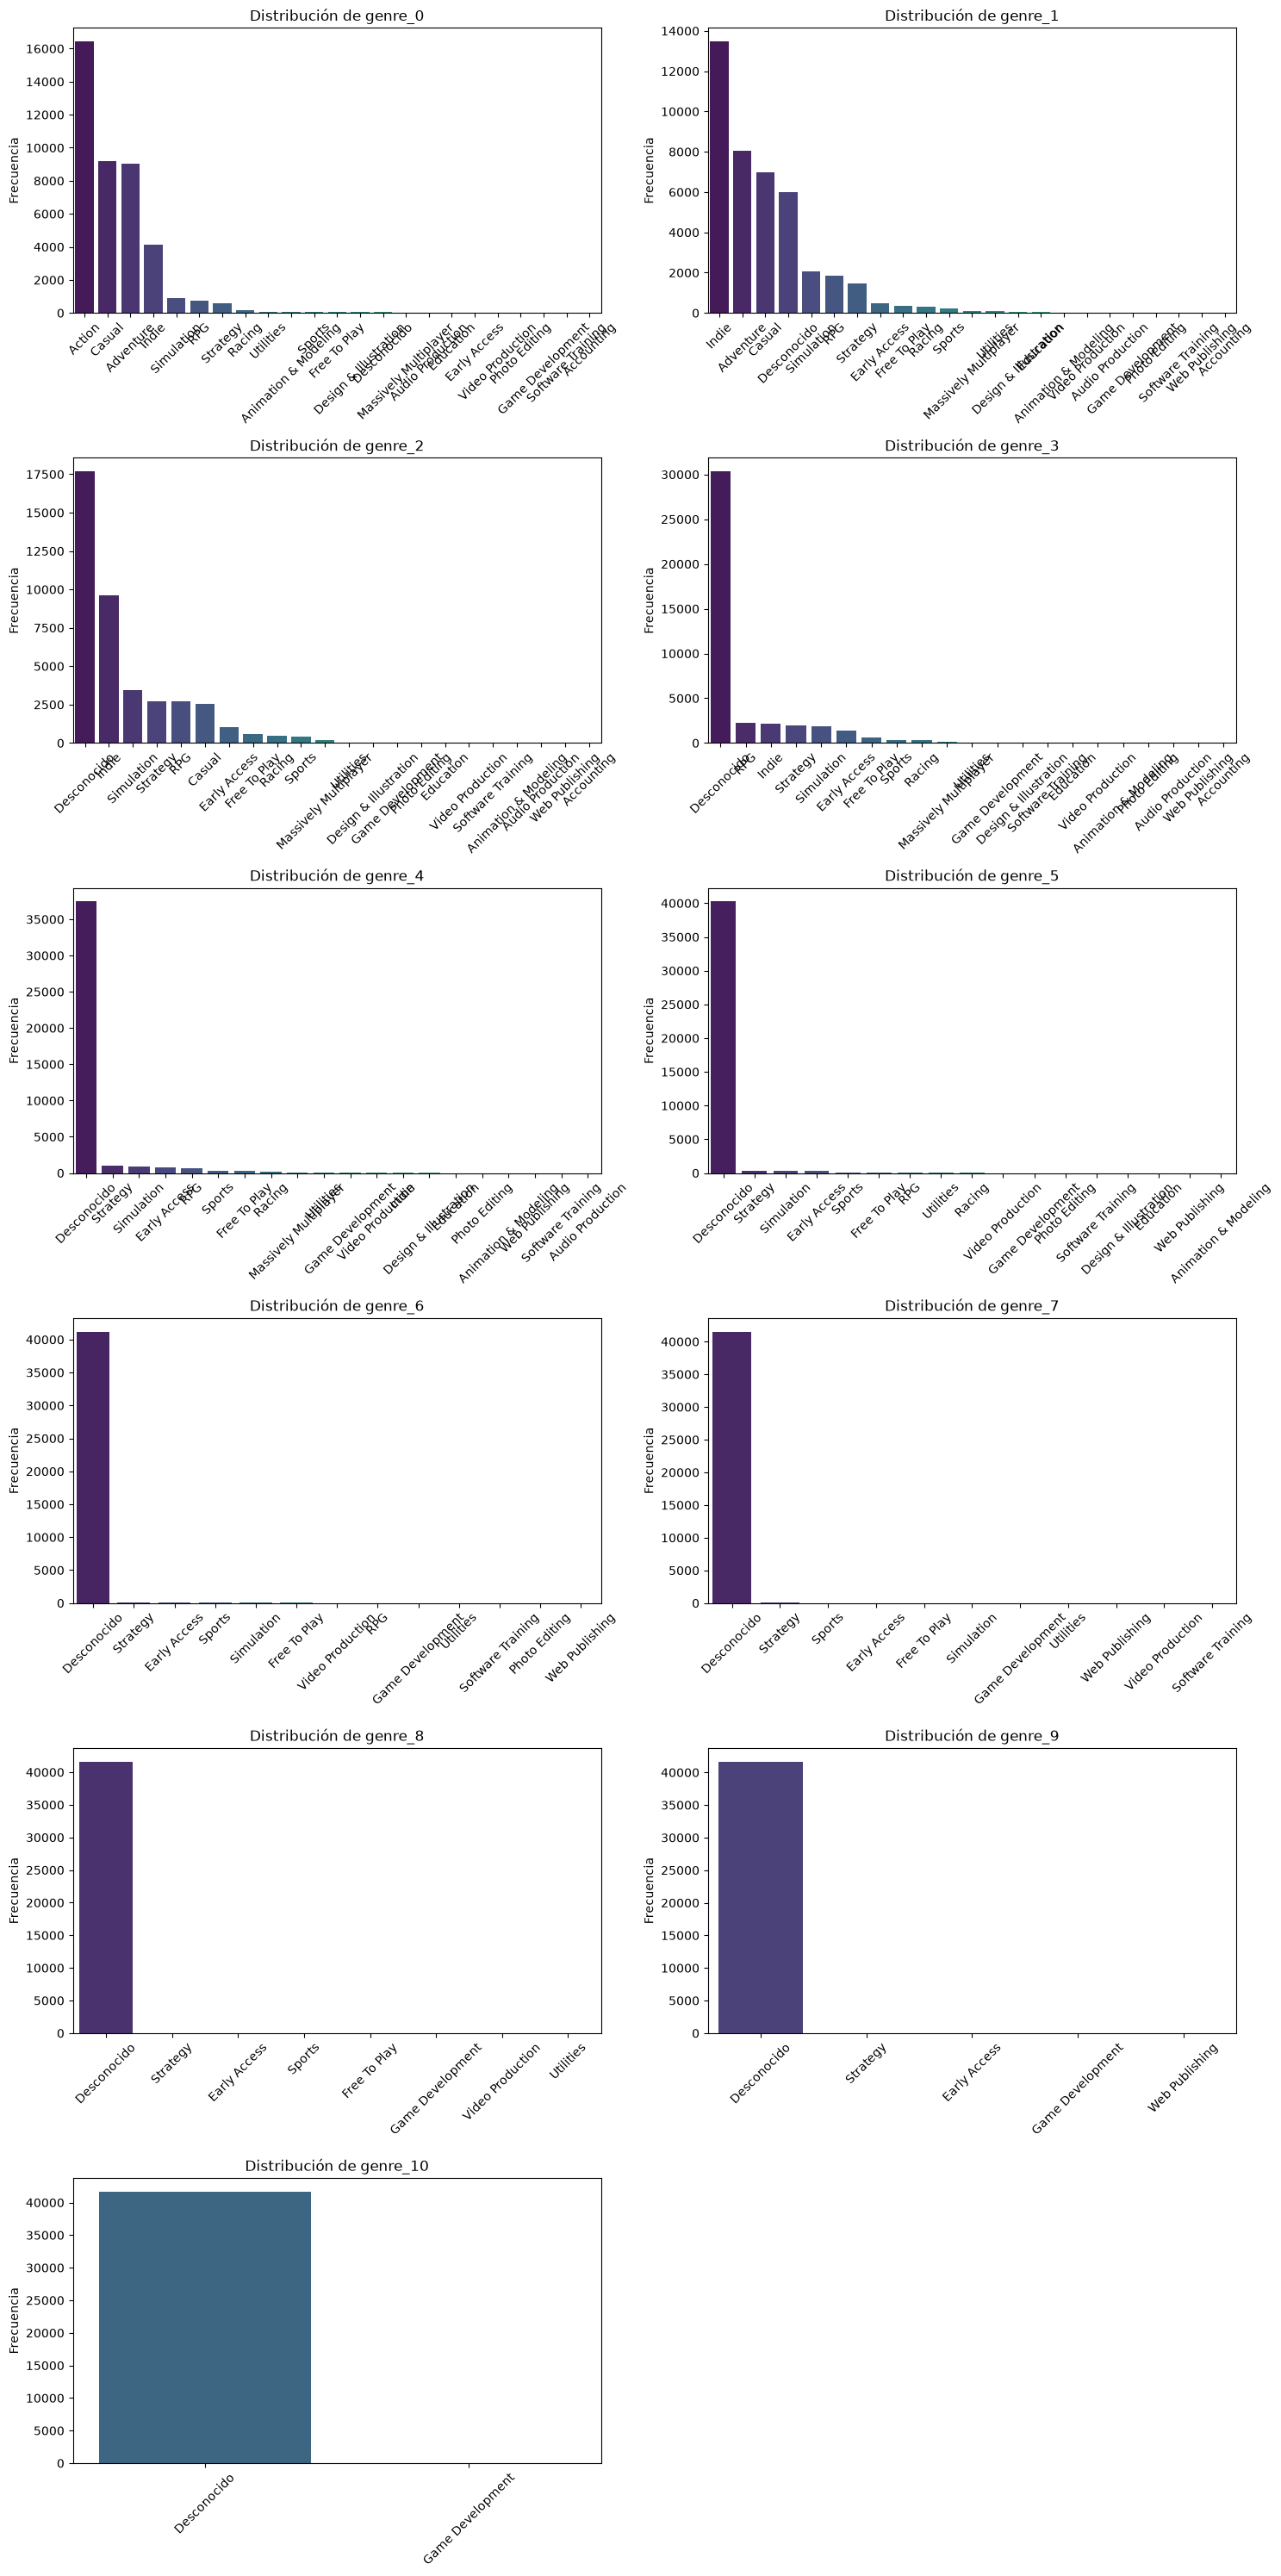

In [21]:
# Vamos a verla distribucion en forma de grafico
utils.pinta_distribucion_categoricas(df, categoricas_generos)

### Observación

Gracias a estos graficos podemos ver como gran cantidad de juegos son del genero **Acción** e **Indie**, y que la mayoría de juegos tienen +1 genero.

#### Vamos a observar las tendencias.

In [22]:
# Primero las medias
df.describe().loc["mean"]

release_date            2024-07-29 03:11:39.407347
estimated_owners_min                  21697.818941
estimated_owners_max                  65276.051539
month                                     6.556206
Name: mean, dtype: object

In [23]:
df.describe().loc["max"]

release_date            2025-12-31 00:00:00
estimated_owners_min             50000000.0
estimated_owners_max            100000000.0
month                                  12.0
Name: max, dtype: object

In [24]:
# Ahora las medianas
df.describe().loc["50%"]

release_date            2024-08-21 00:00:00
estimated_owners_min                    0.0
estimated_owners_max                20000.0
month                                   7.0
Name: 50%, dtype: object

In [25]:
# Y la moda de los generos
df[categoricas_generos].mode().T

,0
genre_0,Action
genre_1,Indie
genre_2,Desconocido
genre_3,Desconocido
genre_4,Desconocido
genre_5,Desconocido
genre_6,Desconocido
genre_7,Desconocido
genre_8,Desconocido
genre_9,Desconocido


In [26]:
# Vamos a sacar el IQR

IQR_mes = utils.sacar_IQR(df, "month")
IQR_owners_min = utils.sacar_IQR(df, "estimated_owners_min")
IQR_owners_max = utils.sacar_IQR(df, "estimated_owners_max")

print("IQR_mes", IQR_mes)
print("IQR_owners_min", IQR_owners_min)
print("IQR_owners_max", IQR_owners_max)

IQR_mes 6.0
IQR_owners_min 0.0
IQR_owners_max 0.0


In [27]:
df.describe().loc["max"] - df.describe().loc["min"]

release_date            1095 days 00:00:00
estimated_owners_min            50000000.0
estimated_owners_max            99980000.0
month                                 11.0
dtype: object

<Axes: title={'center': 'Juegos por mes'}, xlabel='month', ylabel='Cantidad'>

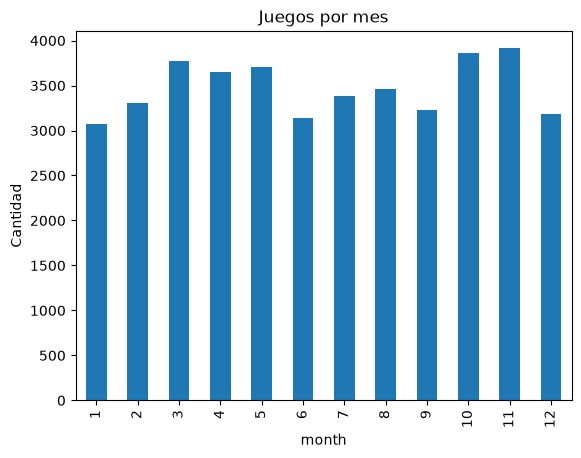

In [28]:
# Vamos a representar la cantidad de juegos por mes
df["month"].value_counts().sort_index().plot(kind="bar", title="Juegos por mes", ylabel="Cantidad")

Y por ultimo, vamos a ver la cantidad de juegos por su numero de owners estimado.

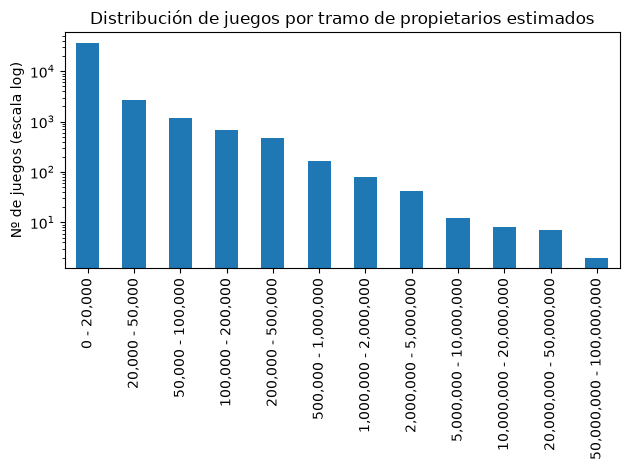

In [29]:
conteo = df.groupby(["estimated_owners_min", "estimated_owners_max"]).size()
conteo.index = [f"{a:,} - {b:,}" for a, b in conteo.index]

conteo.plot(kind="bar", logy=True)
plt.ylabel("Nº de juegos (escala log)")
plt.title("Distribución de juegos por tramo de propietarios estimados")
plt.tight_layout()
plt.show()

### **Observaciones**
Con estos datos vemos como la gran mayoria de juegos, que en noviembre hay mas lanzamientos de juegos, que la gran mayoria son de acción... y que no pasan de 20000 owners.

Vamos a tener que refinar con el Analisis Bivariante.

In [30]:
# Vamos a sacar (aprox.) la cantidad media de owners
df["media_owners"] = (df["estimated_owners_min"] + df["estimated_owners_max"]) / 2

In [31]:
# Vamos a agrupar por mes y sacamos los valores importantes
# Pero primero vamos a descartar los que no superan los 10k

df["mas_10k"] = df["media_owners"] > 10000
groupby_mes = df.groupby("month").agg(
    porciento_exito=("mas_10k", "mean"),
    media_log=("media_owners", lambda x: np.log1p(x).mean()),
    media_recortada=("media_owners", lambda x: x.clip(upper=x.quantile(0.99)).mean()),
    n=("media_owners", "size"),
).reset_index()

print(groupby_mes.sort_values("porciento_exito", ascending=False))

    month  porciento_exito  media_log  media_recortada     n
0       1         0.176643   9.559117     25738.451529  3074
1       2         0.151799   9.520261     24349.863925  3307
3       4         0.149070   9.513464     24157.549234  3656
4       5         0.143590   9.489180     22696.356275  3705
2       3         0.140393   9.498189     23385.084926  3768
8       9         0.127752   9.486725     27772.093023  3225
7       8         0.115929   9.447258     21182.422666  3459
9      10         0.114338   9.446919     21315.789474  3857
6       7         0.113609   9.430829     19813.609467  3380
10     11         0.110657   9.437143     21101.456683  3913
5       6         0.109097   9.437156     20680.661578  3144
11     12         0.100031   9.404476     18775.478206  3189


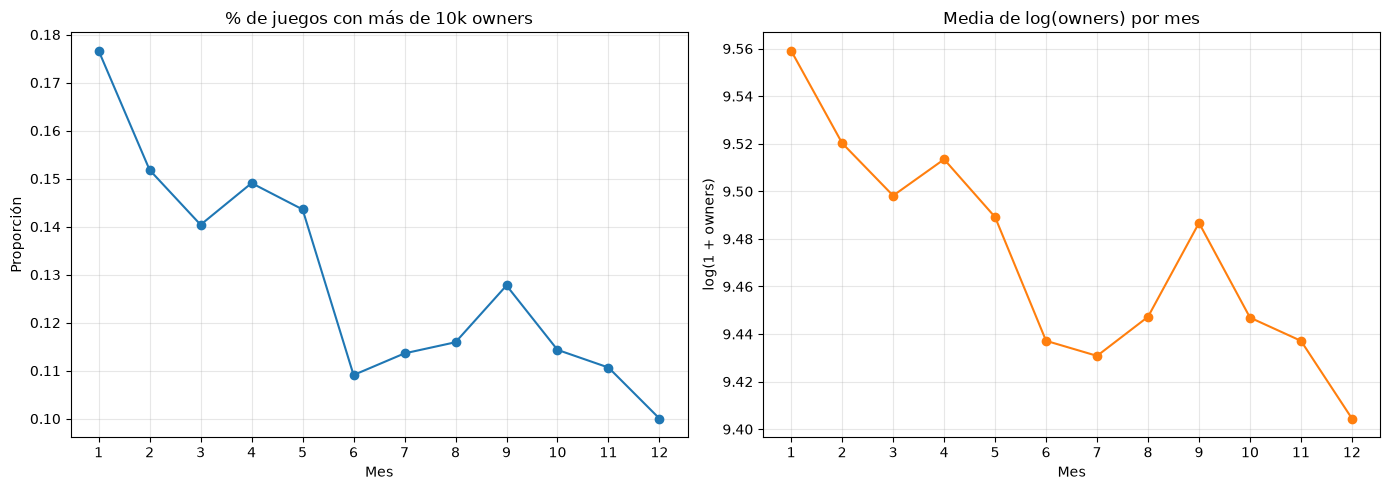

In [32]:
# Vamos a verlo mejor con una grafica

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(groupby_mes["month"], groupby_mes["porciento_exito"], marker="o", linestyle="-")
ax[0].set_title("% de juegos con más de 10k owners")
ax[0].set_xlabel("Mes")
ax[0].set_ylabel("Proporción")
ax[0].set_xticks(range(1, 13))
ax[0].grid(alpha=0.3)

ax[1].plot(groupby_mes["month"], groupby_mes["media_log"], marker="o", linestyle="-", color="tab:orange")
ax[1].set_title("Media de log(owners) por mes")
ax[1].set_xlabel("Mes")
ax[1].set_ylabel("log(1 + owners)")
ax[1].set_xticks(range(1, 13))
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### **Observación**

Según los datos, el mes de **enero** es el mes de lanzamiento donde los juegos cuentan **con mas propietarios.**

**De momento,** es nuestro **mes ideal**.



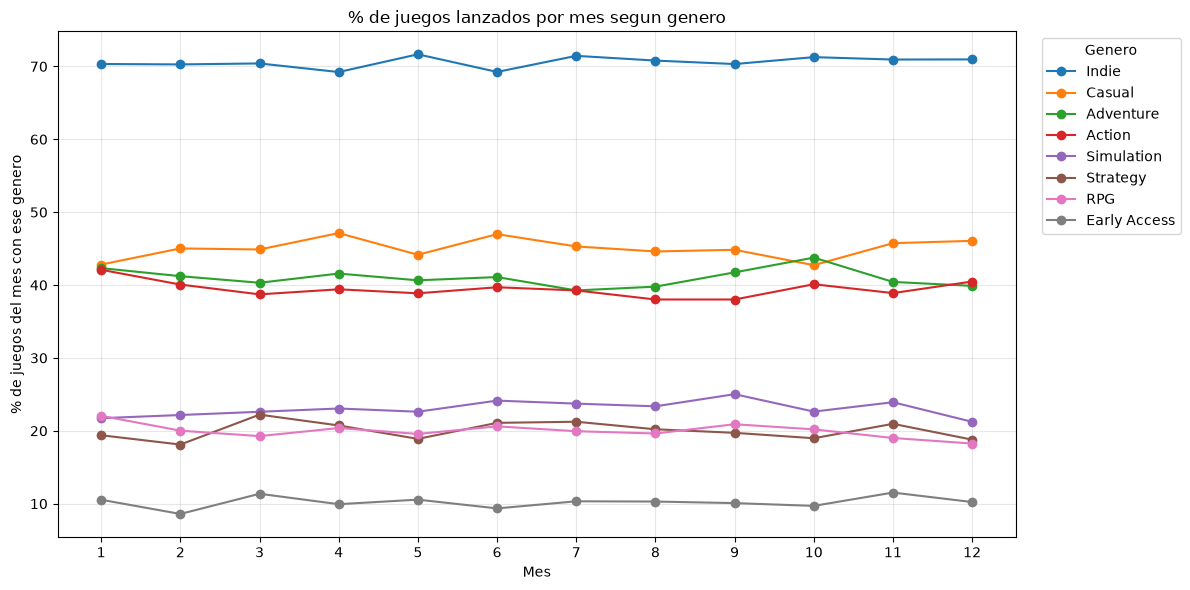

In [33]:
# Vamos a ver que generos son los mas lanzados
# Aqui descartamos "Desconocido" ya que no nos sirve :)

columnas_generos = [f"genre_{i}" for i in range(11)]

# Vamos a hacer una fila por juego/genero, sin usar "Desconocido", ya que no nos sirve.
largo = (
    df.melt(id_vars="month", value_vars=columnas_generos, value_name="genero")
      .query("genero != 'Desconocido'")
)

# Top 8 generos
top = largo["genero"].value_counts().head(8).index

# % de juegos de cada mes por cada genero
tabla = pd.crosstab(largo["month"], largo["genero"])[top]
tabla_porcientos = tabla.div(df.groupby("month").size(), axis=0) * 100

# Tremendo grafico
fig, ax = plt.subplots(figsize=(12, 6))
for g in tabla_porcientos.columns:
    ax.plot(tabla_porcientos.index, tabla_porcientos[g], marker="o", label=g)

ax.set_title("% de juegos lanzados por mes segun genero")
ax.set_xlabel("Mes")
ax.set_ylabel("% de juegos del mes con ese genero")
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.3)
ax.legend(title="Genero", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

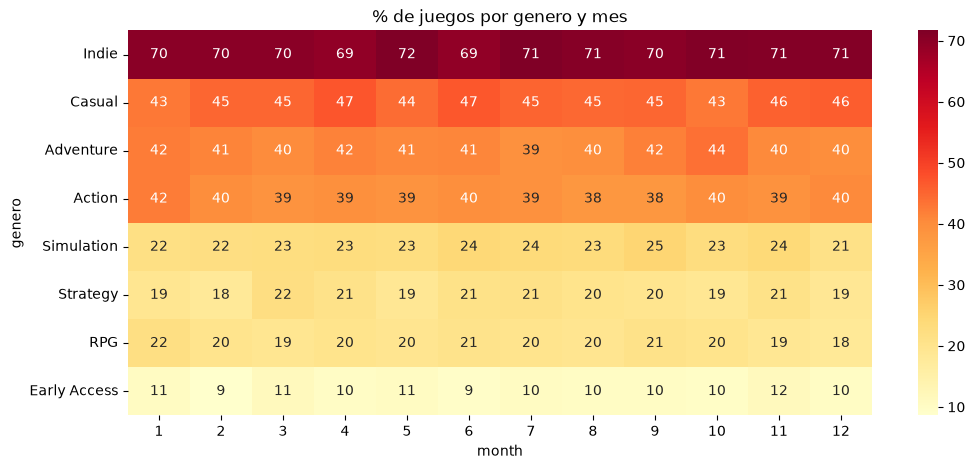

In [34]:
# Y tambien como heatmap, para verlo mas claro.

plt.figure(figsize=(12, 5))
sns.heatmap(tabla_porcientos.T, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("% de juegos por genero y mes")
plt.show()

### Observación

Si ignoramos "Indie" y "Early Access", que son categorías y son, justamente, los extremos, tenemos que hay una gran de cantidad de juegos **"Casual"** y **"Aventuras"**

Ahora vamos a ver si esto se traduce en mas cantidad de jugadores.

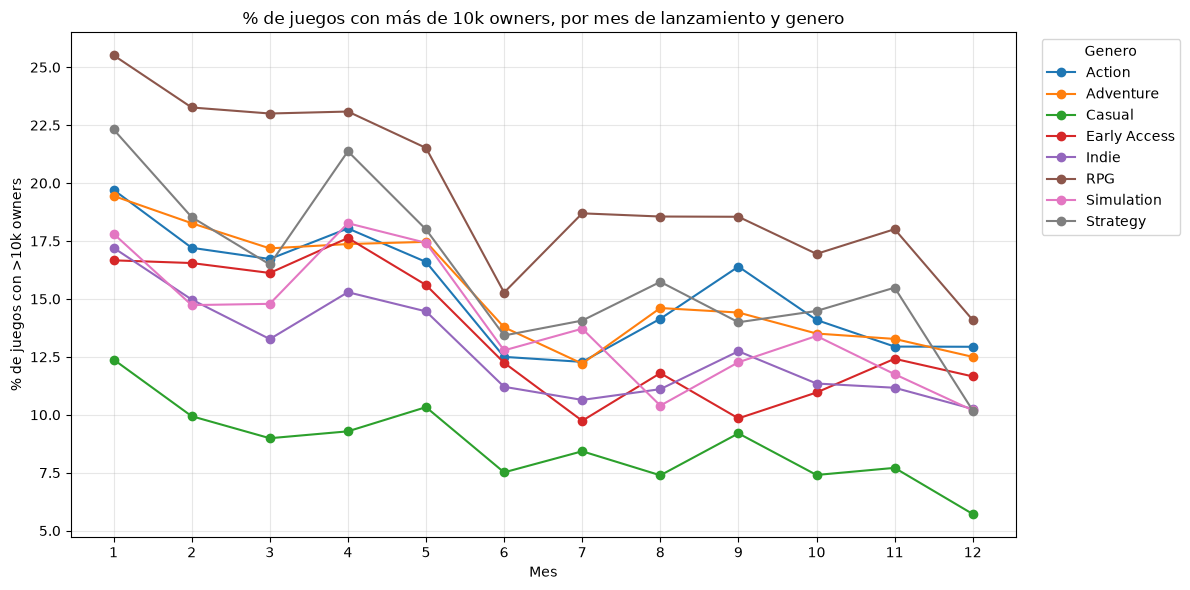

In [35]:
columnas_generos = [f"genre_{i}" for i in range(11)] # Por si acaso la definimos otra vez

largo = (
    df.melt(id_vars=["month", "media_owners", "mas_10k"],
            value_vars=columnas_generos, value_name="genero")
      .query("genero != 'Desconocido'")
)

# Top 8 géneros por número de juegos
top = largo["genero"].value_counts().head(8).index
largo_top = largo[largo["genero"].isin(top)]

# % de éxito por mes y género
exito = (
    largo_top.pivot_table(index="month", columns="genero",
                          values="mas_10k", aggfunc="mean") * 100
)

# Scatter con lineas
fig, ax = plt.subplots(figsize=(12, 6))
for g in exito.columns:
    ax.plot(exito.index, exito[g], marker="o", label=g)

ax.set_title("% de juegos con más de 10k owners, por mes de lanzamiento y genero")
ax.set_xlabel("Mes")
ax.set_ylabel("% de juegos con >10k owners")
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.3)
ax.legend(title="Genero", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

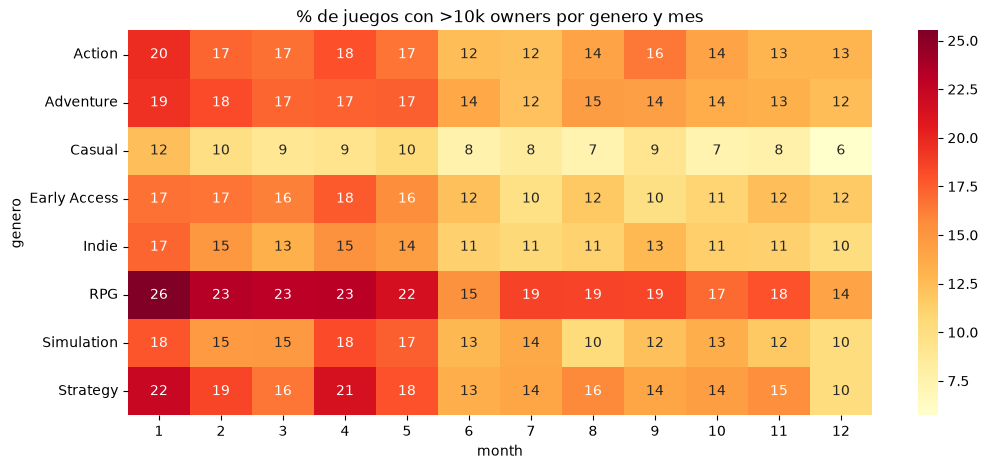

In [36]:
# Y tambien un heatmap que permite verlo mas claro
plt.figure(figsize=(12, 5))
sns.heatmap(exito.T, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("% de juegos con >10k owners por genero y mes")
plt.show()

### Observación

No lo son. Dos reyes surgen en numero de owners: **RPG** y **Estrategía**.

Pero hay algo que destaca. Y es el mes de **Enero**, que sigue saliendo como el top.

Vamos a comprobar si es así o es pura casualidad.

In [37]:
# Primero vamos a sacar una columna con la cantidad
# de juegos que superan los 20k, para descartarnos los de 0

# Para ello, calculamos el valor "medio" de owners
df["media_owners"] = (df["estimated_owners_min"] + df["estimated_owners_max"]) / 2

df["mas_10k"] = (df["media_owners"] > 10000)

df["mas_10k"]

0         False
1          True
3         False
4         False
5         False
          ...  
144258     True
144264    False
144309    False
144324     True
144332    False
Name: mas_10k, Length: 41677, dtype: bool

In [38]:
# Esto ya nos da una idea, pero lo voy a dividir por años
# para mejor uso mas tarde

df["year"] = pd.to_datetime(df["release_date"]).dt.year

df.groupby("year")["mas_10k"].agg(cantidad="size")

,cantidad
year,
2023,11633
2024,15436
2025,14608


In [39]:
# Ahora vamos a hacer una tabla de porcentaje de exito
# para poder representarla, usando la media

tabla_porcentaje = df.pivot_table(index="month", columns="year", values="mas_10k", aggfunc="mean") * 100

tabla_porcentaje

year,2023,2024,2025
month,,,
1,24.094881,18.441815,12.946783
2,19.596865,16.572352,10.365336
3,20.591133,14.346712,9.608091
4,19.871795,15.264527,11.678366
5,18.697479,15.045593,10.855950
6,18.506132,12.739965,2.815622
7,19.189765,14.296998,1.955782
8,19.132150,13.680297,2.090909
9,19.736842,15.095847,2.842640


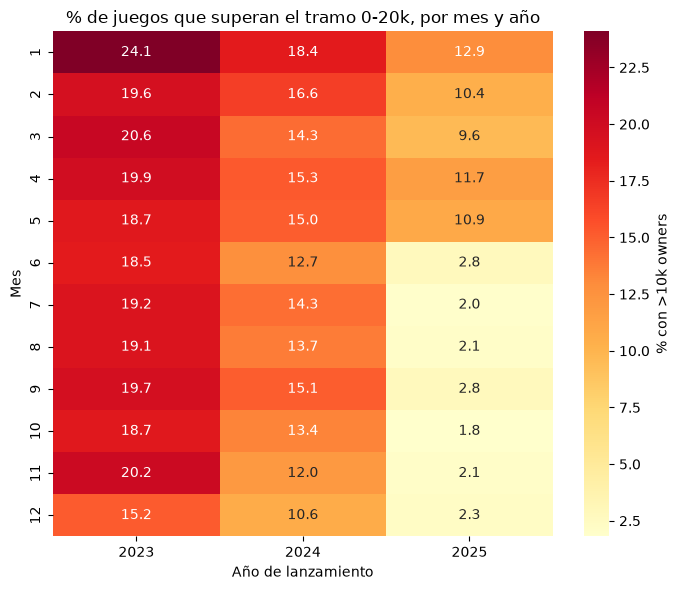

In [40]:
# Adelante, grafico!
plt.figure(figsize=(7, 6))
sns.heatmap(tabla_porcentaje, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% con >10k owners"})
plt.title("% de juegos que superan el tramo 0-20k, por mes y año")
plt.xlabel("Año de lanzamiento") 
plt.ylabel("Mes")
plt.tight_layout() 
plt.show()

No importa el año, siempre sale Enero.

Vamos a hacer dos hipótesis:

O **el mes NO tiene nada que ver con el exito**, o **Enero ES clave**

In [41]:
# Para ello, voy a usar la chi_contingency

# Voy a guardarme los resultados, por si acaso.
resultados = []
# recorro los datos para poder guardar los datos
for i in [2023, 2024, 2025]:
    datos = df[df["year"] == i].copy() # Para evitar borrar los datos
    datos["grupo"] = np.where(datos["month"] == 1, "Enero", "Resto") # Asi puesto para diferenciar si es Enero o no

    # Ahora si, vamos a hacer la contingencia chi2 (?) (Tremenda traduccion acabo de poner)
    pvalor_mes = chi2_contingency(pd.crosstab(datos["month"], datos["mas_10k"]))[1]

    print("Año:", i, ", pvalor:", pvalor_mes)

    # Vamos con la hipotesis numero 2

    datos2 = pd.crosstab(datos["grupo"], datos["mas_10k"])
    
    # Como chi2_contingency devuelve un objeto, lo guardo para sacar sus resultados
    contingency_datos = chi2_contingency(datos2)

    resultado = contingency_datos[0]
    pvalor_chi2 = contingency_datos[1]
    frecuencia_esperada = contingency_datos[3]

    print("----")
    print("chi2: ", resultado)
    print("pvalor de la contingencia:", pvalor_chi2)
    print("frecuencia minima esperada:", frecuencia_esperada.min())
    print("-----")

    # Y ahora vamos a ver si Enero es el mejor mes para conseguir compradores
    # Para ello sacamos la media

    porcentaje = datos.groupby("grupo")["mas_10k"].mean() * 100

    print("Porcentaje en Enero:", porcentaje["Enero"])
    print("Porcentaje el resto de meses:", porcentaje["Resto"],"\n")

    # Mejor en diccionario, mas facil para cargar datos
    resultados.append({"año": i,
                        "Enero": porcentaje["Enero"],
                        "Resto": porcentaje["Resto"],
                        "pvalor": pvalor_chi2})


Año: 2023 , pvalor: 0.008101216631374326
----
chi2:  11.844343340108429
pvalor de la contingencia: 0.0005783676699514764
frecuencia minima esperada: 155.33877761540444
-----
Porcentaje en Enero: 24.094881398252184
Porcentaje el resto de meses: 19.04542097488922 

Año: 2024 , pvalor: 1.7847828017333603e-06
----
chi2:  16.257439346221453
pvalor de la contingencia: 5.529206488341287e-05
frecuencia minima esperada: 143.27118424462296
-----
Porcentaje en Enero: 18.441814595660748
Porcentaje el resto de meses: 13.826099015393151 

Año: 2025 , pvalor: 2.0389773632799375e-96
----
chi2:  93.79315128898885
pvalor de la contingencia: 3.502817500695384e-22
frecuencia minima esperada: 81.6178121577218
-----
Porcentaje en Enero: 12.946783161239079
Porcentaje el resto de meses: 5.873099108547457 



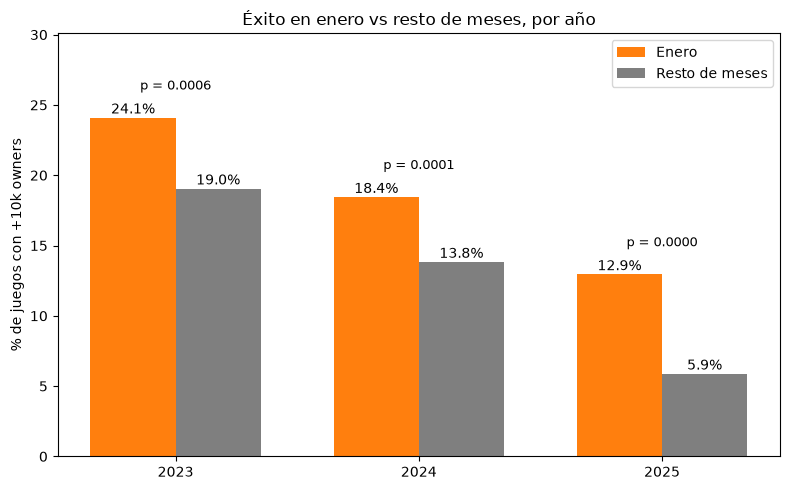

In [42]:
# Vamos a representarlo en una grafica bien bonita
# Para ello, vamos a usar la lista (diccionario) que guardamos antes.

df_resultados = pd.DataFrame(resultados)
x = np.arange(len(resultados)) # Para la X creo la lista desde 0 hasta el tamaño
ancho = 0.35

# Grafico go go go
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - ancho/2, df_resultados["Enero"], ancho, label="Enero", color="tab:orange")
ax.bar(x + ancho/2, df_resultados["Resto"], ancho, label="Resto de meses", color="tab:gray")

for j, fila in df_resultados.iterrows():
    ax.text(j - ancho/2, fila["Enero"] + 0.3, f"{fila['Enero']:.1f}%", ha="center")
    ax.text(j + ancho/2, fila["Resto"] + 0.3, f"{fila['Resto']:.1f}%", ha="center")
    ax.text(j, max(fila["Enero"], fila["Resto"]) + 2, f"p = {fila['pvalor']:.4f}", ha="center", fontsize=9)

ax.set_xticks(x); ax.set_xticklabels(df_resultados["año"])
ax.set_ylabel("% de juegos con +10k owners")
ax.set_title("Éxito en enero vs resto de meses, por año")
ax.set_ylim(0, df_resultados[["Enero", "Resto"]].max().max() + 6)
ax.legend()
plt.tight_layout()
plt.show()

### Observación:

Al ver que los p-valores son inferiores a 0,05, se ve que, efectivamente, **el mes de lanzamiento si que tiene que ver con el numero de owners**, por lo que **Enero es clave**.

Ahora vamos a sacar que genero es el que (posiblemente) mas exito tiene.

In [43]:
columnas_generos = [f"genre_{i}" for i in range(11)] # Me gusta rehacerlo por si acaso.
largo = (df
         .melt(id_vars=["year", "month", "mas_10k"], value_vars=columnas_generos, value_name="genero")
         .query("genero != 'Desconocido'"))

resumen = (largo.groupby("genero")["mas_10k"].agg(n="size", porcentaje_exito="mean")
           .assign(porcentaje_exito=lambda t: 100 * t["porcentaje_exito"]) # lo convierto a tanto por 100
           .sort_values("n", ascending=False).head(10))
print("Media global 2023-2025:", round(100 * df["mas_10k"].mean(), 1), "%")

Media global 2023-2025: 12.9 %


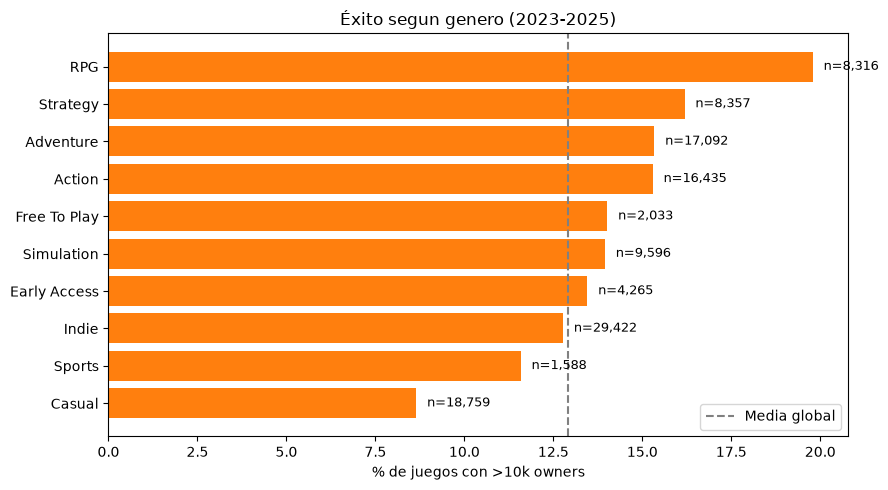

In [44]:
# Y ahora si, vamos a ordenarlos, y a sacar una bonita grafica.

orden = resumen.sort_values("porcentaje_exito").index
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(orden, resumen.loc[orden, "porcentaje_exito"], color="tab:orange")
for i, g in enumerate(orden):
    ax.text(resumen.loc[g, "porcentaje_exito"] + 0.3, i, f"n={resumen.loc[g, 'n']:,}", va="center", fontsize=9)
ax.axvline(100 * df["mas_10k"].mean(), color="gray", linestyle="--", label="Media global")
ax.set_xlabel("% de juegos con >10k owners"); ax.set_title("Éxito segun genero (2023-2025)")
ax.legend()
plt.tight_layout()
plt.show()

### Observacion
Los generos con mayor porcentaje de owners sin duda son **RPG** y **Estrategia**, con una clara victoria de **RPG**.

### Conclusión final

- Si sacas un juego Casual, lamentablemente hay tantos que habría que esforzarse muchisimo.
- Lo ideal, sería sacar un juego **RPG** en **Enero**.
- La hipotesis inicial de que un juego Shooter en Septiembre-Octubre no es una buena idea, ya que sería competir con el peso pesado que es Call of Duty.